# Agentic AI for Autonomous Investment Research

## Planner and Agent Orchestration with Real Specialists

The Planner creates a validated research plan; the Orchestrator routes only selected work and grants each specialist only its planned tools. Market and earnings calculations are deterministic. News runs as an explicit five-stage prompt chain and keeps every intermediate result.

Groq and Hugging Face API clients are the default. Leave `LLM_PROVIDER` unset to select a configured Groq client first, then Hugging Face; set `LLM_PROVIDER=local` only to opt into the optional local Qwen backend. Add credentials to a local `.env` file (see `.env.example`).

The integration status table distinguishes real implementations from placeholders and unimplemented Engineer 3 report/memory handoffs. Educational research only; not personalized investment advice.

In [25]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

for module_name in list(sys.modules):
    if module_name == 'src' or module_name.startswith('src.'):
        del sys.modules[module_name]

try:
    import truststore
    truststore.inject_into_ssl()
except ImportError:
    pass

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.bootstrap import build_runtime
from src.orchestration_viz import (
    plan_table, routing_table, tool_log_table, execution_table,
    plot_plan, plot_routing_matrix, plot_execution_timeline, plot_tool_calls,
)

pd.set_option('display.max_colwidth', 90)
pd.set_option('display.width', 160)

rt = build_runtime(allow_stubs=False)
print('LLM provider:', rt.llm.provider, '| model:', rt.llm.model)
print('Integration status (real, stub, or missing):')
display(pd.Series(rt.integration, name='status').to_frame())

LLM provider: Groq | model: openai/gpt-oss-120b
Integration status (real, stub, or missing):


,status
memory,missing
market_agent,real
earnings_agent,real
news_agent,real
data_tools,real
llm,Groq
report_pipeline,missing


## 1. Planning

A broad request produces a plan that covers every specialist.

Planner mode: llm | scope: comprehensive
Intent      : Provide comprehensive investment research for MSFT
Rationale   : The question asks for comprehensive investment research, so all three specialized agents are required to cover market performance, financial fundamentals, and recent news.


,step,subagent,description,depends_on,tools,completion_criteria,status
0,S1,market_agent,"Gather price history, benchmark history, compute performance metrics and include macro...",-,"get_price_history, get_benchmark_history, get_macro_series","Price history, benchmark data, volatility, trends, and macro series retrieved and summ...",pending
1,S2,earnings_agent,"Retrieve financial statements and SEC filings, analyze income, balance sheet, and cash...",-,"get_financial_statements, get_sec_filings",Financial statements and SEC filings downloaded and key financial metrics calculated,pending
2,S3,news_agent,"Collect recent company news, identify catalysts and risks, and produce a source‑backed...",-,get_company_news,Latest news items gathered and five‑stage analysis completed,pending


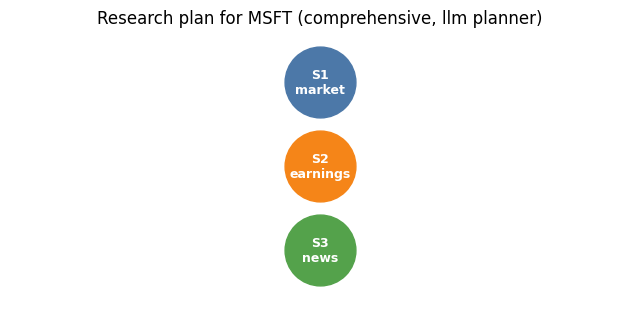

In [26]:
state = rt.orchestrator.plan('MSFT', 'Produce comprehensive investment research')
print('Planner mode:', state.plan.planner_mode, '| scope:', state.plan.scope)
print('Intent      :', state.plan.intent)
print('Rationale   :', state.plan.rationale)
display(plan_table(state.plan))
plot_plan(state.plan)
plt.show()
for w in state.warnings:
    print('WARNING:', w.source, '-', w.message)

Each step has a concrete completion criterion and the exact tools the subagent may call. The plan is validated (known subagents, allowed tools, unique ids, no dependency cycles) before anything runs.

## 2. Routing: narrow questions select narrow sets

Six questions, including an earnings-before-market execution dependency and a macro question that adds an optional tool.

The dependency example demonstrates scheduling only. The specialists compute annual financial trends and configured-period market metrics; they do not isolate price movements around an earnings announcement or attribute those movements to earnings.

Analyze one-year price performance
   S1 market_agent: tools=['get_price_history', 'get_benchmark_history']
Analyze revenue and margin trends
   S1 earnings_agent: tools=['get_financial_statements']
Summarize recent product announcements
   S1 news_agent: tools=['get_company_news']
Analyze earnings and the resulting share-price movement
   S1 earnings_agent: tools=['get_financial_statements']
   S2 market_agent (after S1): tools=['get_price_history', 'get_benchmark_history']
Analyze price performance given interest rates and inflation
   S1 market_agent: tools=['get_price_history', 'get_benchmark_history', 'get_macro_series']
Produce comprehensive investment research
   S1 market_agent: tools=['get_price_history', 'get_benchmark_history', 'get_macro_series']
   S2 earnings_agent: tools=['get_financial_statements', 'get_sec_filings']
   S3 news_agent: tools=['get_company_news']


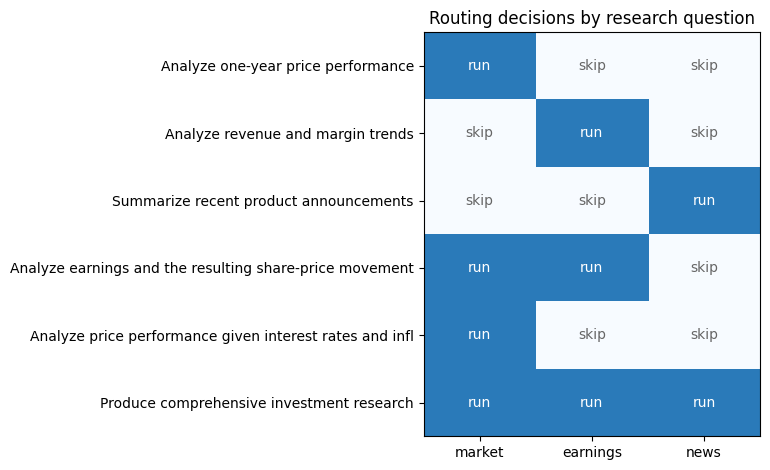

In [27]:
QUESTIONS = [
    'Analyze one-year price performance',
    'Analyze revenue and margin trends',
    'Summarize recent product announcements',
    'Analyze earnings and the resulting share-price movement',
    'Analyze price performance given interest rates and inflation',
    'Produce comprehensive investment research',
]

cases = {}
for q in QUESTIONS:
    s = rt.orchestrator.plan('AAPL', q)
    cases[q] = s.routing_log
    print(f'{q}')
    for step in s.plan.steps:
        dep = f' (after {", ".join(step.depends_on)})' if step.depends_on else ''
        print(f'   {step.step_id} {step.subagent}{dep}: tools={step.tools}')

plot_routing_matrix(cases, rt.subagents.names())
plt.show()

In [28]:
# Selected AND skipped subagents, each with a reason and confidence.
display(routing_table(cases[QUESTIONS[3]]))
display(routing_table(cases[QUESTIONS[0]]))

,decision,subagent,task,reason,confidence,status
0,SELECTED,earnings_agent,"Retrieve and analyze AAPL's most recent earnings report, summarizing revenue, profit, ...",Earnings information is required to assess performance before examining price reaction.,0.92,pending
1,SELECTED,market_agent,"Measure AAPL's share-price movement around the earnings release, calculating price cha...",Price reaction analysis depends on knowing the earnings release date from the previous...,0.90,pending
2,skipped,news_agent,none,Company news is not explicitly needed for an earnings and price‑movement analysis.,0.80,pending


,decision,subagent,task,reason,confidence,status
0,SELECTED,market_agent,Retrieve AAPL and benchmark price histories for the past 12 months and compute total r...,Needed to quantify the one‑year price performance as requested.,0.9,pending
1,skipped,earnings_agent,none,Earnings data is not required for a pure price‑performance analysis.,0.8,pending
2,skipped,news_agent,none,Recent news is not needed to answer the one‑year price performance question.,0.8,pending


The matrix shows routing is conditional: the number of selected subagents changes with the question, so this is not a fixed pipeline. The optional macro tool appears only for the macro question.

## 3. Lessons from earlier runs shape the plan

The Planner receives lessons from Memory (Engineer 3) as guidance, never as evidence. The lesson below is a hand-written stand-in to show the mechanism; real lessons come from run reflection.

In [29]:
lesson = [{
    'memory_id': 'DEMO-1',
    'lesson': 'Price-only answers lacked event context; include recent news.',
    'score': 0.9,
    'hint': {'require_subagents': ['news_agent'], 'extra_criteria': 'state data limitations explicitly'},
}]
q = 'Analyze one-year price performance'
before = rt.planner.create_plan('AAPL', q)
after = rt.planner.create_plan('AAPL', q, lesson)
print('Without lesson:', before.plan.selected_subagents)
print('With lesson   :', after.plan.selected_subagents, '| lessons applied:', after.plan.lessons_applied)
display(routing_table(after.routing))

Without lesson: ['market_agent']
With lesson   : ['market_agent', 'news_agent'] | lessons applied: ['DEMO-1']


,decision,subagent,task,reason,confidence,status
0,SELECTED,market_agent,Retrieve and compute one-year price performance metrics for AAPL and its benchmark,Market data is required to analyze price performance,0.90,pending
1,SELECTED,news_agent,Gather and summarize recent news affecting AAPL over the past year,"Lesson DEMO-1 indicates price‑only answers lack event context, so news is added",0.85,pending
2,skipped,earnings_agent,none,Financial statement analysis not required for pure price performance question,0.80,pending


## 4. Orchestration and Dynamic Tool Use

The Orchestrator runs steps in dependency order. Each subagent gets a tool session limited to the tools in its plan step; every call is logged with status, duration and a result summary.

,step_id,subagent,status,started_at,duration_ms,tools_allowed,tool_calls,message
0,S1,earnings_agent,success,2026-10-12T17:49:43+00:00,31.04,[get_financial_statements],1,"For the fiscal year ended 2026-06-30, MSFT reported revenue of USD 331.8 bn (+17.8% ye..."
1,S2,market_agent,success,2026-10-12T17:49:43+00:00,22.27,"[get_price_history, get_benchmark_history]",2,"MSFT returned +6.0% from 2025-10-13 to 2026-10-12 against +18.6% for SPY, with 32.8% a..."


,caller,tool_name,status,duration_ms,output_summary,error,retrieved_at
0,orchestrator,get_company_profile,success,1.67,dict with 13 keys,None,2026-10-12T17:49:43+00:00
1,earnings_agent,get_financial_statements,success,2.37,"DataFrame shape=(4, 9)",None,2026-10-12T17:49:43+00:00
2,market_agent,get_price_history,success,2.54,"DataFrame shape=(251, 5)",None,2026-10-12T17:49:43+00:00
3,market_agent,get_benchmark_history,success,2.46,"DataFrame shape=(251, 5)",None,2026-10-12T17:49:43+00:00


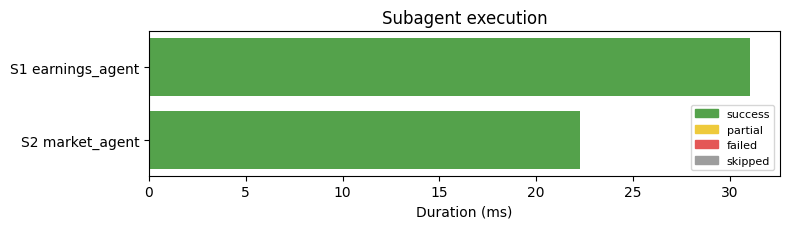

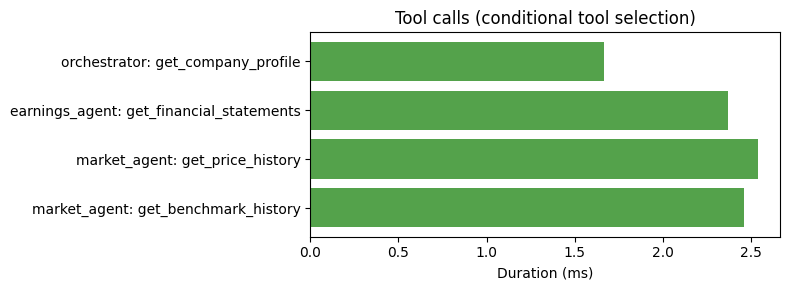

Subagents that ran: ['earnings_agent', 'market_agent']
News tool called?   False


In [30]:
state = rt.orchestrator.run('MSFT', 'Analyze earnings and the resulting share-price movement')
display(execution_table(state))
display(tool_log_table(state))
plot_execution_timeline(state)
plt.show()
plot_tool_calls(state)
plt.show()
print('Subagents that ran:', state.selected_subagents)
print('News tool called?  ', any(c['tool_name'] == 'get_company_news' for c in state.tool_call_log))

## 5. Real Specialist Outputs and News Prompt Chain

Run a comprehensive request to execute the real market, earnings, and news specialists. The chart payloads and each news-chain stage remain available in the aggregated state; missing feeds or model credentials appear as partial coverage.

,step_id,subagent,status,started_at,duration_ms,tools_allowed,tool_calls,message
0,S1,market_agent,success,2026-10-12T17:49:59+00:00,16.04,"[get_price_history, get_benchmark_history, get_macro_series]",3,"MSFT returned +6.0% from 2025-10-13 to 2026-10-12 against +18.6% for SPY, with 32.8% a..."
1,S2,earnings_agent,success,2026-10-12T17:49:59+00:00,11.73,"[get_financial_statements, get_sec_filings]",2,"For the fiscal year ended 2026-06-30, MSFT reported revenue of USD 331.8 bn (+17.8% ye..."
2,S3,news_agent,success,2026-10-12T17:49:59+00:00,200927.86,[get_company_news],1,Microsoft is facing regulatory pressure as the Trump administration suspends its parti...


,caller,tool_name,status,duration_ms,output_summary,error,retrieved_at
0,orchestrator,get_company_profile,success,1.09,dict with 13 keys,None,2026-10-12T17:49:59+00:00
1,market_agent,get_price_history,success,1.34,"DataFrame shape=(251, 5)",None,2026-10-12T17:49:59+00:00
2,market_agent,get_benchmark_history,success,1.28,"DataFrame shape=(251, 5)",None,2026-10-12T17:49:59+00:00
3,market_agent,get_macro_series,success,1.66,"DataFrame shape=(248, 1)",None,2026-10-12T17:49:59+00:00
4,earnings_agent,get_financial_statements,success,1.28,"DataFrame shape=(4, 9)",None,2026-10-12T17:49:59+00:00
5,earnings_agent,get_sec_filings,success,1.50,"DataFrame shape=(4, 4)",None,2026-10-12T17:49:59+00:00
6,news_agent,get_company_news,success,1626.27,dict with 5 keys,None,2026-10-12T17:50:01+00:00


Coverage: {'market_agent': 'success', 'earnings_agent': 'success', 'news_agent': 'success'}
Company profile: Microsoft Corporation | Technology | USD
Finding evidence references resolve: True | unresolved: []


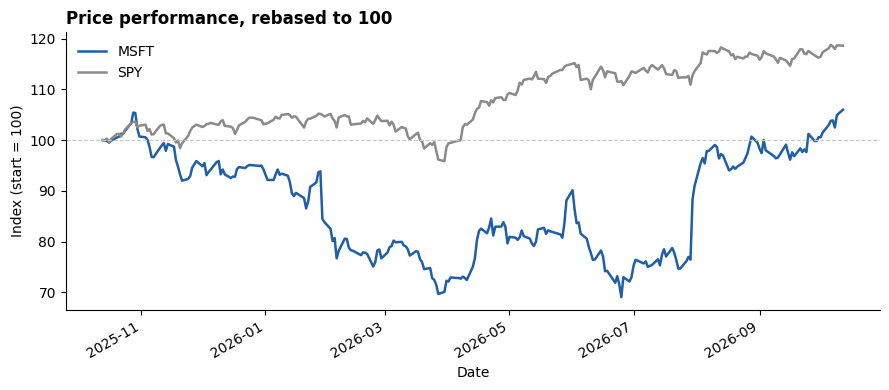

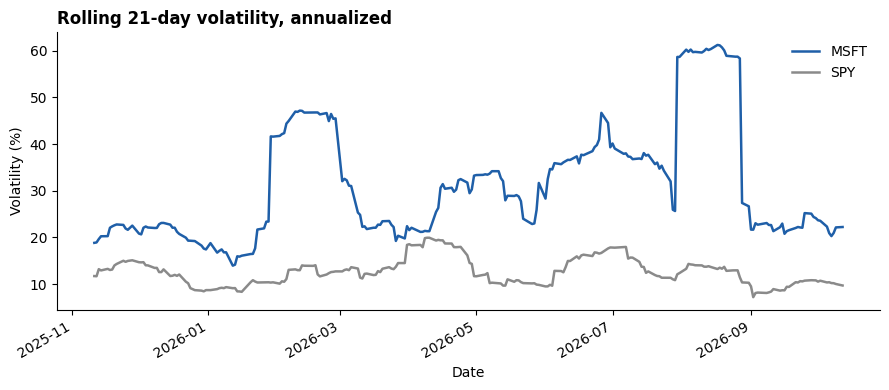

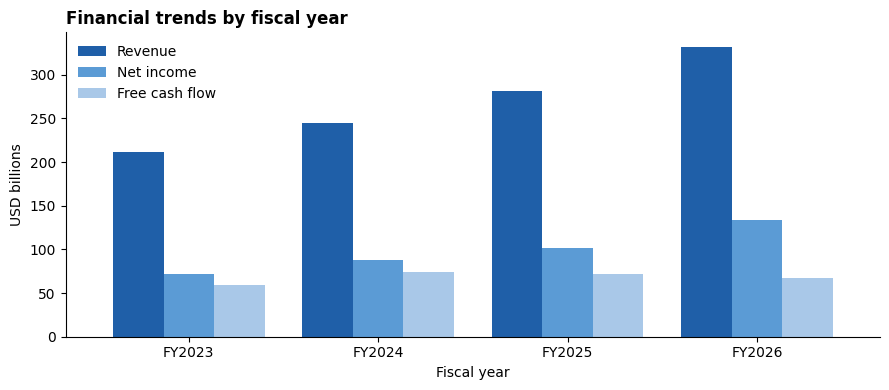

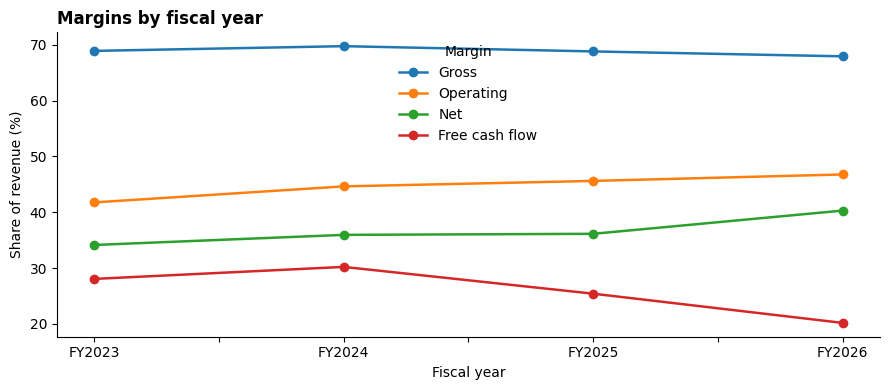

News summary: Microsoft is facing regulatory pressure as the Trump administration suspends its participation in a green‑card program and includes the firm in a broader foreign‑worker crackdown, raising hiring and compliance concerns [E1][E2][E10]. Despite these setbacks, the company was recognized as a Leader in Gartner’s 2026 Magic Quadrant for Global Industrial AIoT Platforms, underscoring its strength in AI‑enabled industrial solutions [E3]. Microsoft also announced a suite of product initiatives, including the expansion of its Azure Maia system to multi‑gigawatt deployments and the launch of its custom Maia 300 AI chip designed to reduce reliance on Nvidia and AMD [E4][E6][E8]. The firm plans to deploy these chips at scale to cut costs and further lessen dependence on external suppliers, a strategy echoed in multiple reports [E5][E7]. Overall, the recent news presents a mix of negative regulatory challenges and strong positive product and market recognitions, leaving the net impact

,id,title,summary,publisher,url,published_at,source_feed,retrieved_at,duplicate_count,also_reported_by,event_type,relevance,impact,time_horizon
0,A001,It Now Takes $4.4B To Make the Forbes 400: See America's 10 Richest People,,MoneyLion,https://finance.yahoo.com/markets/stocks/articles/now-takes-4-4b-forbes-170028016.html,2026-10-11 17:00:28+00:00,yahoo_finance,2026-10-12T17:50:01+00:00,1,[],None,None,None,None
1,A002,Does Everforth (EFOR) Embedding Screening in Workday Deepen Its Consulting-Led Platfor...,,Simply Wall St.,https://finance.yahoo.com/technology/ai/articles/does-everforth-efor-embedding-screeni...,2026-10-11 16:08:51+00:00,yahoo_finance,2026-10-12T17:50:01+00:00,1,[],None,None,None,None
2,A003,What Could Microsoft (MSFT) Green Card Suspension Mean For Hiring And Compliance?,,Simply Wall St.,https://finance.yahoo.com/technology/articles/could-microsoft-msft-green-card-16083670...,2026-10-11 16:08:36+00:00,yahoo_finance,2026-10-12T17:50:01+00:00,1,[],None,None,None,None
3,A004,America’s $6 Trillion Interest-Rate Trap Is Spreading Far Beyond the Bond Market — and...,,24/7 Wall St.,https://finance.yahoo.com/markets/stocks/articles/america-6-trillion-interest-rate-145...,2026-10-11 14:58:02+00:00,yahoo_finance,2026-10-12T17:50:01+00:00,1,[],None,None,None,None
4,A005,Ray Dalio Warns Stocks Are Running Out of Room for Error — and AI Could Make It Worse,,24/7 Wall St.,https://finance.yahoo.com/markets/stocks/articles/ray-dalio-warns-stocks-running-14473...,2026-10-11 14:47:32+00:00,yahoo_finance,2026-10-12T17:50:01+00:00,1,[],None,None,None,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
120,A121,"AI doesn't have rights or feelings — nor should it, Microsoft's AI chief says - CBS News",,CBS News,https://news.google.com/rss/articles/CBMidkFVX3lxTE1EbERZc2prMmExQm9aYWV5OFVteHBUVlJiS...,2026-09-16 07:00:00+00:00,google_news,2026-10-12T17:50:01+00:00,1,[],None,None,None,None
121,A122,"Microsoft’s blazing stock comeback isn’t even close to being over, analyst says - Mark...",,MarketWatch,https://news.google.com/rss/articles/CBMiuwFBVV95cUxPbkJHbk1yUE5ITDljR1ptUjBzQXQ0Z0p1c...,2026-10-05 21:27:00+00:00,google_news,2026-10-12T17:50:01+00:00,1,[],None,None,None,None
122,A123,​​Beyond source code: A path to the keys to the kingdom - Microsoft,,Microsoft,https://news.google.com/rss/articles/CBMirwFBVV95cUxQX1AzNVVUWkxFaGxpYlhvR3p0NTRPR2NId...,2026-09-29 07:00:00+00:00,google_news,2026-10-12T17:50:01+00:00,1,[],None,None,None,None
123,A124,"OpenAI, Microsoft fend off part of software developer lawsuit over AI training - Reuters",,Reuters,https://news.google.com/rss/articles/CBMixgFBVV95cUxNbUNoRUZpb0NvNUtWS1hEZEt2d3ByaTFxM...,2026-09-16 07:00:00+00:00,google_news,2026-10-12T17:50:01+00:00,1,[],None,None,None,None


Clean (12 records)


,id,title,summary,publisher,url,published_at,source_feed,retrieved_at,duplicate_count,also_reported_by,event_type,relevance,impact,time_horizon
0,A107,"The Trump administration is suspending Microsoft from a green card program, alleging f...",,AP News,https://news.google.com/rss/articles/CBMilwFBVV95cUxOSlNGOUJHbkJ0UXdETE9EUWMySjZkMWVzX...,2026-10-09 00:07:00+00:00,google_news,2026-10-12T17:50:01+00:00,2,[NBC News],None,None,None,None
1,A090,"Trump's foreign worker crackdown comes for Microsoft, Adobe, IT firms",,Axios,https://news.google.com/rss/articles/CBMioAFBVV95cUxOTHBUeWVBdWg1NlRjbm0wVUJSSFlGeVRMc...,2026-10-08 18:13:38+00:00,google_news,2026-10-12T17:50:01+00:00,2,[CNBC],None,None,None,None
2,A110,Microsoft named a Leader in the 2026 Gartner® Magic Quadrant™ for Global Industrial AI...,,Microsoft Azure,https://news.google.com/rss/articles/CBMi0gFBVV95cUxPT1JNOE9HUEdHLTFvdUV4TDZkTGtfMXdDZ...,2026-10-06 21:00:00+00:00,google_news,2026-10-12T17:50:01+00:00,2,[],None,None,None,None
3,A058,Microsoft to expand Azure Maia system to multi-gigawatt deployments,,The Official Microsoft Blog,https://news.google.com/rss/articles/CBMisgFBVV95cUxNQWtCRTJBSThLQjBSa09qbEhKc2d2N0xyM...,2026-10-12 17:24:05+00:00,google_news,2026-10-12T17:50:01+00:00,1,[],None,None,None,None
4,A069,"Microsoft plans huge deployment of its own AI chips, with an eye on saving costs",,Reuters,https://news.google.com/rss/articles/CBMiugFBVV95cUxPWHVSM1ltUmRIUHVldm04ZU5JX2hLc0lhY...,2026-10-12 15:06:26+00:00,google_news,2026-10-12T17:50:01+00:00,1,[],None,None,None,None
5,A100,Microsoft CEO’s AI Warning Draws Little Reaction From Cybersecurity Stocks,,Barron's,https://news.google.com/rss/articles/CBMilAFBVV95cUxQcU40WWVIbGg1aV9TZEpwamdsZXVfZ2hme...,2026-10-12 14:18:00+00:00,google_news,2026-10-12T17:50:01+00:00,1,[],None,None,None,None
6,A053,Before - Microsoft's latest custom chip: Maia 300,,Microsoft Source,https://news.google.com/rss/articles/CBMiTkFVX3lxTE1tWUJXcEE5b0haaGRtb2NjNjlrOHJrb2IyY...,2026-10-12 13:19:24+00:00,google_news,2026-10-12T17:50:01+00:00,1,[],None,None,None,None
7,A075,"Microsoft to rely more on homegrown AI chips, reducing dependence on Nvidia",,CNBC,https://news.google.com/rss/articles/CBMimgFBVV95cUxQbXdvdGREcjRPNHptRzBRc0U2a3ZSZXQ5c...,2026-10-12 13:00:01+00:00,google_news,2026-10-12T17:50:01+00:00,1,[],None,None,None,None
8,A103,"Microsoft reveals Maia 300 AI chip as it works to reduce dependence on Nvidia, AMD",,Yahoo Finance,https://news.google.com/rss/articles/CBMi2AFBVV95cUxPdzlOWjZPREptdmhCandwSVY1VlRpbGZfb...,2026-10-12 13:00:00+00:00,google_news,2026-10-12T17:50:01+00:00,1,[],None,None,None,None
9,A096,"AI is less regulated than milk, says Microsoft president",,BBC,https://news.google.com/rss/articles/CBMiW0FVX3lxTFBWblVtb0hnbURUVU1uMXNTMmFyUmxwUGNET...,2026-10-12 07:47:37+00:00,google_news,2026-10-12T17:50:01+00:00,1,[],None,None,None,None


Classified (12 records)


,id,title,summary,publisher,url,published_at,source_feed,retrieved_at,duplicate_count,also_reported_by,event_type,relevance,impact,time_horizon
0,A107,"The Trump administration is suspending Microsoft from a green card program, alleging f...",,AP News,https://news.google.com/rss/articles/CBMilwFBVV95cUxOSlNGOUJHbkJ0UXdETE9EUWMySjZkMWVzX...,2026-10-09 00:07:00+00:00,google_news,2026-10-12T17:50:01+00:00,2,[NBC News],regulatory_legal,high,negative,medium_term
1,A090,"Trump's foreign worker crackdown comes for Microsoft, Adobe, IT firms",,Axios,https://news.google.com/rss/articles/CBMioAFBVV95cUxOTHBUeWVBdWg1NlRjbm0wVUJSSFlGeVRMc...,2026-10-08 18:13:38+00:00,google_news,2026-10-12T17:50:01+00:00,2,[CNBC],regulatory_legal,high,negative,medium_term
2,A110,Microsoft named a Leader in the 2026 Gartner® Magic Quadrant™ for Global Industrial AI...,,Microsoft Azure,https://news.google.com/rss/articles/CBMi0gFBVV95cUxPT1JNOE9HUEdHLTFvdUV4TDZkTGtfMXdDZ...,2026-10-06 21:00:00+00:00,google_news,2026-10-12T17:50:01+00:00,2,[],analyst_rating,high,positive,short_term
3,A058,Microsoft to expand Azure Maia system to multi-gigawatt deployments,,The Official Microsoft Blog,https://news.google.com/rss/articles/CBMisgFBVV95cUxNQWtCRTJBSThLQjBSa09qbEhKc2d2N0xyM...,2026-10-12 17:24:05+00:00,google_news,2026-10-12T17:50:01+00:00,1,[],product,high,positive,medium_term
4,A069,"Microsoft plans huge deployment of its own AI chips, with an eye on saving costs",,Reuters,https://news.google.com/rss/articles/CBMiugFBVV95cUxPWHVSM1ltUmRIUHVldm04ZU5JX2hLc0lhY...,2026-10-12 15:06:26+00:00,google_news,2026-10-12T17:50:01+00:00,1,[],product,high,positive,medium_term
5,A100,Microsoft CEO’s AI Warning Draws Little Reaction From Cybersecurity Stocks,,Barron's,https://news.google.com/rss/articles/CBMilAFBVV95cUxQcU40WWVIbGg1aV9TZEpwamdsZXVfZ2hme...,2026-10-12 14:18:00+00:00,google_news,2026-10-12T17:50:01+00:00,1,[],market_commentary,low,neutral,short_term
6,A053,Before - Microsoft's latest custom chip: Maia 300,,Microsoft Source,https://news.google.com/rss/articles/CBMiTkFVX3lxTE1tWUJXcEE5b0haaGRtb2NjNjlrOHJrb2IyY...,2026-10-12 13:19:24+00:00,google_news,2026-10-12T17:50:01+00:00,1,[],product,high,positive,medium_term
7,A075,"Microsoft to rely more on homegrown AI chips, reducing dependence on Nvidia",,CNBC,https://news.google.com/rss/articles/CBMimgFBVV95cUxQbXdvdGREcjRPNHptRzBRc0U2a3ZSZXQ5c...,2026-10-12 13:00:01+00:00,google_news,2026-10-12T17:50:01+00:00,1,[],product,high,positive,medium_term
8,A103,"Microsoft reveals Maia 300 AI chip as it works to reduce dependence on Nvidia, AMD",,Yahoo Finance,https://news.google.com/rss/articles/CBMi2AFBVV95cUxPdzlOWjZPREptdmhCandwSVY1VlRpbGZfb...,2026-10-12 13:00:00+00:00,google_news,2026-10-12T17:50:01+00:00,1,[],product,high,positive,medium_term
9,A096,"AI is less regulated than milk, says Microsoft president",,BBC,https://news.google.com/rss/articles/CBMiW0FVX3lxTFBWblVtb0hnbURUVU1uMXNTMmFyUmxwUGNET...,2026-10-12 07:47:37+00:00,google_news,2026-10-12T17:50:01+00:00,1,[],other,medium,neutral,short_term


Events (11 records)


,id,article_id,event,event_date,entities,figures,dates_mentioned,risks,catalysts,event_type,relevance,impact,time_horizon,source,url,retrieved_at,extraction_method
0,E1,A107,"The Trump administration is suspending Microsoft from a green card program, alleging f...",2026-10-09,"[Trump administration, Microsoft]",[],[],"[Risk of reduced access to skilled immigration talent, Potential reputational damage]",[],regulatory_legal,high,negative,medium_term,AP News,https://news.google.com/rss/articles/CBMilwFBVV95cUxOSlNGOUJHbkJ0UXdETE9EUWMySjZkMWVzX...,2026-10-12T17:50:01+00:00,llm
1,E2,A090,"Trump's foreign worker crackdown targets Microsoft, Adobe, and other IT firms.",2026-10-08,"[Trump, Microsoft, Adobe, IT firms]",[],[],[Potential hiring restrictions for foreign workers],[],regulatory_legal,high,negative,medium_term,Axios,https://news.google.com/rss/articles/CBMioAFBVV95cUxOTHBUeWVBdWg1NlRjbm0wVUJSSFlGeVRMc...,2026-10-12T17:50:01+00:00,llm
2,E3,A110,Microsoft was named a Leader in the 2026 Gartner Magic Quadrant for Global Industrial ...,2026-10-06,"[Microsoft, Gartner]",[],[2026],[Increased pressure to maintain leadership position],[Enhanced market credibility may drive sales],analyst_rating,high,positive,short_term,Microsoft Azure,https://news.google.com/rss/articles/CBMi0gFBVV95cUxPT1JNOE9HUEdHLTFvdUV4TDZkTGtfMXdDZ...,2026-10-12T17:50:01+00:00,llm
3,E4,A058,Microsoft plans to expand its Azure Maia system to multi-gigawatt deployments.,2026-10-12,"[Microsoft, Azure Maia]",[],[],"[Execution risk in scaling the system, High capital expenditure risk]","[Growing demand for large-scale cloud infrastructure, Potential revenue boost from exp...",product,high,positive,medium_term,The Official Microsoft Blog,https://news.google.com/rss/articles/CBMisgFBVV95cUxNQWtCRTJBSThLQjBSa09qbEhKc2d2N0xyM...,2026-10-12T17:50:01+00:00,llm
4,E5,A069,Microsoft plans to deploy its own AI chips on a large scale to save costs.,2026-10-12,[AI chips],[],[],"[Potential technical or production challenges with new AI chips, Supply chain constrai...","[Cost savings from in‑house chip usage, Improved AI performance and differentiation]",product,high,positive,medium_term,Reuters,https://news.google.com/rss/articles/CBMiugFBVV95cUxPWHVSM1ltUmRIUHVldm04ZU5JX2hLc0lhY...,2026-10-12T17:50:01+00:00,llm
5,E6,A053,Microsoft announced its latest custom chip named Maia 300.,2026-10-12,"[Microsoft, Maia 300]",[],[],[],[],product,high,positive,medium_term,Microsoft Source,https://news.google.com/rss/articles/CBMiTkFVX3lxTE1tWUJXcEE5b0haaGRtb2NjNjlrOHJrb2IyY...,2026-10-12T17:50:01+00:00,llm
6,E7,A075,"Microsoft plans to rely more on its own AI chips, reducing its dependence on Nvidia.",2026-10-12,"[Microsoft, Nvidia]",[],[],"[Potential performance shortfall of in‑house chips, Loss of Nvidia technology support]","[Improved margins from lower chip costs, Greater control over AI hardware roadmap]",product,high,positive,medium_term,CNBC,https://news.google.com/rss/articles/CBMimgFBVV95cUxQbXdvdGREcjRPNHptRzBRc0U2a3ZSZXQ5c...,2026-10-12T17:50:01+00:00,llm
7,E8,A103,Microsoft reveals Maia 300 AI chip to reduce dependence on Nvidia and AMD.,2026-10-12,"[Maia 300 AI chip, Nvidia, AMD]",[],[],"[Technical development risk, Potential lower performance versus established GPUs]","[Diversification from Nvidia/AMD suppliers, Potential margin improvement from in‑house...",product,high,positive,medium_term,Yahoo Finance,https://news.google.com/rss/articles/CBMi2AFBVV95cUxPdzlOWjZPREptdmhCandwSVY1VlRpbGZfb...,2026-10-12T17:50:01+00:00,llm
8,E9,A096,Microsoft president said AI is less regulated than milk.,2026-10-12,"[Microsoft, Microsoft president]",[],[],"[Potential regulatory scrutiny due to lax oversight, Reputational risk if AI harms occur]",[Accelerated AI development and deployment],other,medium,neutral,short_term,BBC,https://news.google.com/rss/articles/CBMiW0FVX3lxTFBWblVtb0hnbURUVU1uMXNTMmFyUmxwUGNET...,2026-10-12T17:50:01+00:00,llm
9,E10,A003,Microsoft faces a green card suspension 

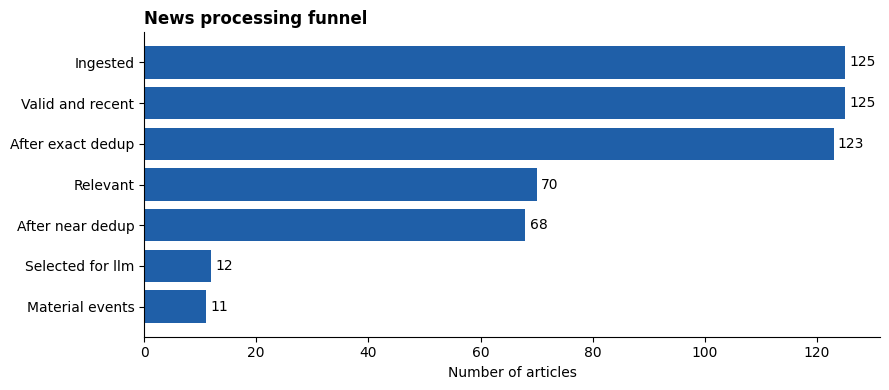

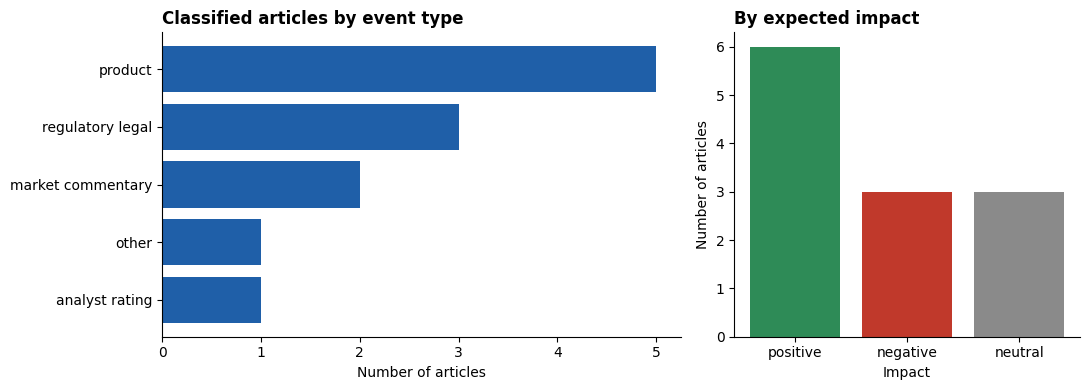

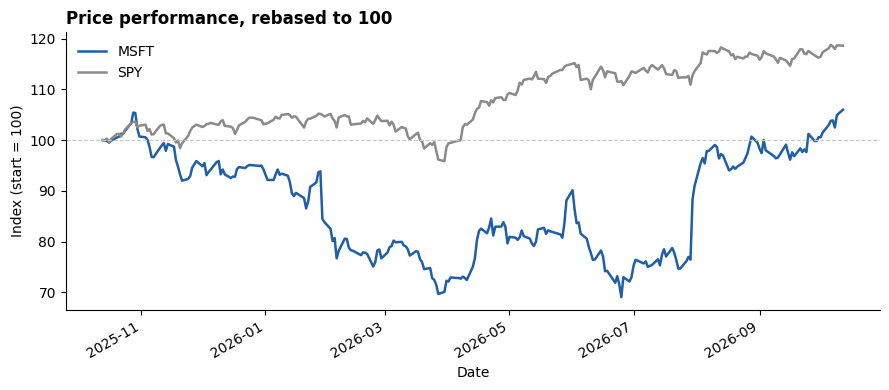

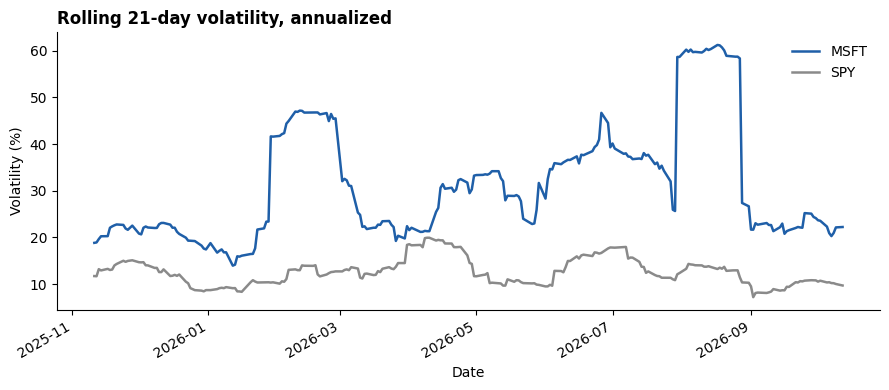

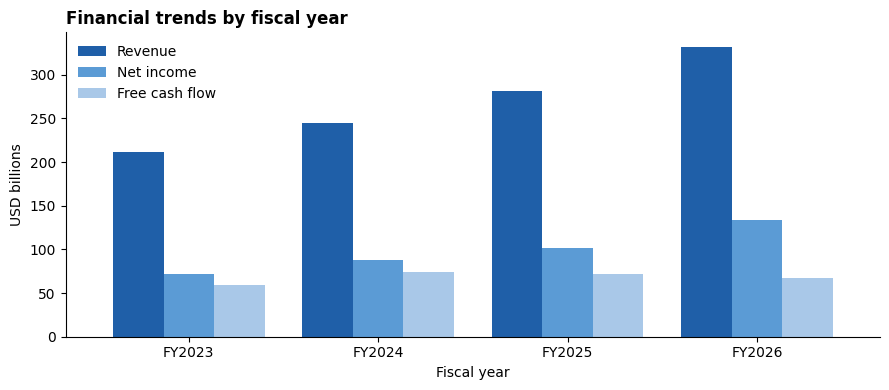

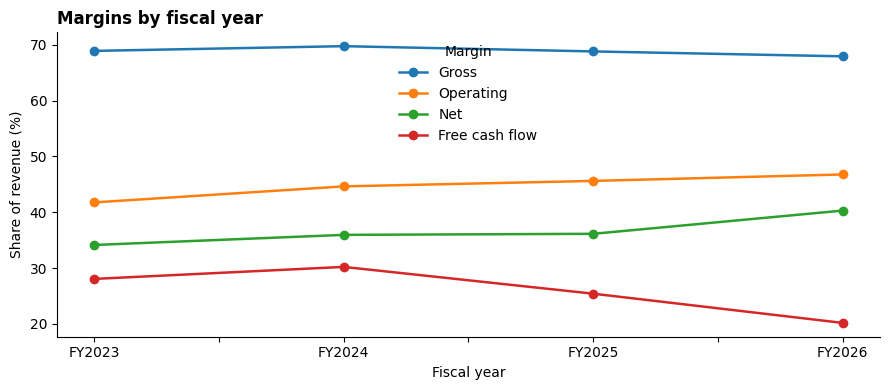

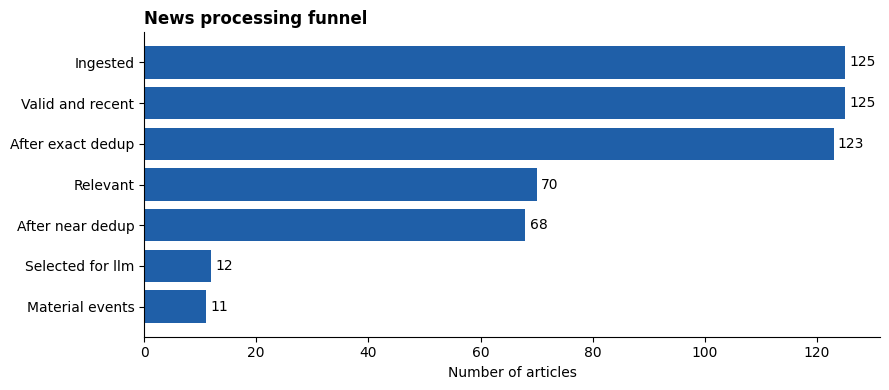

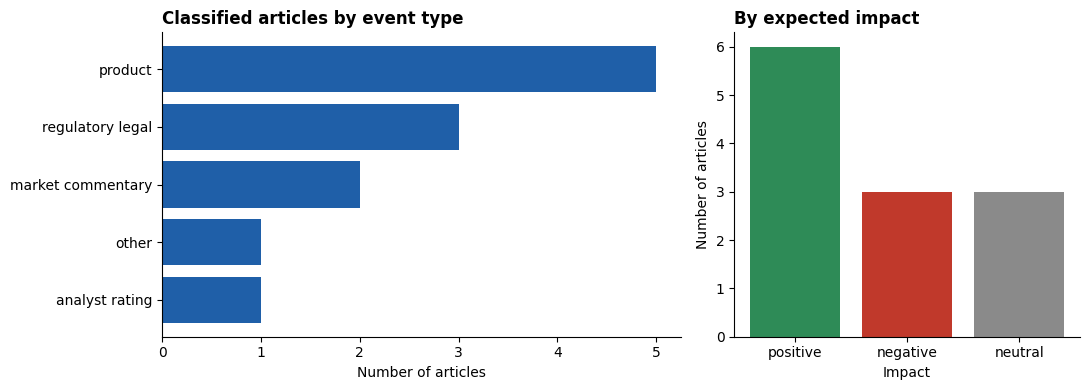

In [31]:
from src.visualizations import (
    plot_financial_trends, plot_margins, plot_news_categories, plot_news_funnel,
    plot_performance, plot_rolling_volatility,
)

comprehensive_state = rt.orchestrator.run('MSFT', 'Produce comprehensive investment research')
display(execution_table(comprehensive_state))
display(tool_log_table(comprehensive_state))
print('Coverage:', comprehensive_state.aggregated['coverage'])
profile = comprehensive_state.company_profile or {}
print('Company profile:', profile.get('name', 'unavailable'), '|', profile.get('sector'), '|', profile.get('currency'))
evidence_ids = {item.get('id') or item.get('evidence_id') for item in comprehensive_state.aggregated['evidence']}
cited_ids = {
    evidence_id
    for finding in comprehensive_state.aggregated['findings']
    for evidence_id in finding.get('evidence_ids', [])
}
unresolved_citations = sorted(cited_ids - evidence_ids)
print('Finding evidence references resolve:', not unresolved_citations, '| unresolved:', unresolved_citations)

visuals = comprehensive_state.aggregated['visualization_data']
market_visuals = visuals.get('market_agent', {})
if 'performance' in market_visuals:
    display(plot_performance(market_visuals['performance']))
    display(plot_rolling_volatility(market_visuals['rolling_volatility']))

earnings_visuals = visuals.get('earnings_agent', {})
if 'financial_trends' in earnings_visuals:
    display(plot_financial_trends(earnings_visuals['financial_trends'], earnings_visuals['currency']))
    display(plot_margins(earnings_visuals['margins']))

news_visuals = visuals.get('news_agent', {})
news_stages = news_visuals.get('stages', {})
if news_stages:
    print('News summary:', news_stages['summary']['summary'])
    print('News feed errors:', news_stages['feed_errors'])
    for stage in ('raw', 'clean', 'classified', 'events'):
        records = news_stages[stage]
        print(f'{stage.title()} ({len(records)} records)')
        rows = [record.model_dump() if callable(getattr(record, 'model_dump', None)) else record for record in records]
        display(pd.DataFrame(rows))
    display(plot_news_funnel(news_visuals['funnel']))
    category_values = []
    impact_values = []
    for article in news_stages['classified']:
        if isinstance(article, dict):
            event_type, impact = article.get('event_type'), article.get('impact')
        else:
            event_type, impact = article.event_type, article.impact
        if event_type:
            category_values.append(event_type)
        if impact:
            impact_values.append(impact)
    categories = pd.Series(category_values).value_counts().to_dict()
    impacts = pd.Series(impact_values).value_counts().to_dict()
    if categories or impacts:
        display(plot_news_categories(categories, impacts))
else:
    print('News stages unavailable:', [warning.message for warning in comprehensive_state.warnings])

Only the earnings and market tools were called; the news tool never ran because the plan did not select it.

## 5. Partial failure does not stop the workflow

The News subagent is replaced with one that raises an error. The other subagents still complete; the failure becomes a warning and a limitation for the report.

In [32]:
original_news_agent = rt.subagents.get('news_agent').fn

def failing_news_agent(state, tools, step):
    raise RuntimeError('simulated news API outage')

rt.subagents.attach('news_agent', failing_news_agent)
try:
    failed_run = rt.orchestrator.run('AAPL', 'Produce comprehensive investment research')
finally:
    rt.subagents.attach('news_agent', original_news_agent)

display(execution_table(failed_run)[['step_id', 'subagent', 'status', 'tool_calls', 'message']])
print('Coverage   :', failed_run.aggregated['coverage'])
print('Limitations:')
for item in failed_run.aggregated['limitations']:
    print('  -', item['agent'], ':', item['text'])
print('Errors     :', [w.message for w in failed_run.warnings if w.severity == 'error'])

,step_id,subagent,status,tool_calls,message
0,S1,market_agent,success,3,"AAPL returned +37.6% from 2025-10-13 to 2026-10-12 against +18.6% for SPY, with 24.5% ..."
1,S2,earnings_agent,success,2,"For the fiscal year ended 2025-09-30, AAPL reported revenue of USD 416.2 bn (+6.4% yea..."
2,S3,news_agent,failed,0,RuntimeError: simulated news API outage


Coverage   : {'market_agent': 'success', 'earnings_agent': 'success', 'news_agent': 'failed'}
Limitations:
  - market_agent : Based on adjusted daily closes from 2025-10-13 to 2026-10-12; past performance does not predict future returns.
  - market_agent : SPY is a broad-market benchmark and may not reflect the company's sector.
  - earnings_agent : Based on 4 annual periods through 2025-09-30; later quarterly results are not reflected.
  - earnings_agent : Line items are Yahoo Finance's standardized values and can differ from company-reported figures.
  - news_agent : news_agent did not complete (failed); no analysis available.
Errors     : ['Subagent failed: RuntimeError: simulated news API outage']


## 6. Hand-off to the Report Generator

`state.aggregated` is the single structure Engineer 3 consumes: per-agent status, findings, risks, limitations, de-duplicated evidence with ids, coverage, warnings and memories used. When `src/report_generator.py` exposes `run_report_pipeline(state)`, `build_runtime()` wires it in automatically.

In [33]:
agg = state.aggregated
print({k: (len(v) if isinstance(v, (list, dict)) else v) for k, v in agg.items() if k not in ('question',)})
print('Report pipeline:', rt.integration['report_pipeline'])

{'symbol': 'MSFT', 'company_profile': 13, 'agents': 2, 'coverage': 2, 'findings': 11, 'risks': 2, 'catalysts': 0, 'limitations': 4, 'evidence': 23, 'visualization_data': 2, 'warnings': 0, 'memories_used': 0, 'aggregated_at': '2026-10-12T17:49:43+00:00'}
Report pipeline: missing
